In [1]:
# Importation des bibliotheques importantes
from pathlib import Path
from urllib.request import urlretrieve
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Bibliothèques importées avec succès !") 

Bibliothèques importées avec succès !


# Telechargement des fichiers 

In [2]:
# Création du dossier du projet
dossier = Path("projet_tarification_auto")
dossier.mkdir(parents=True, exist_ok=True)

# Adresse des fichiers
base_url = "https://huggingface.co/datasets/mabilton/fremtpl2/resolve/main/"

fichiers = {
    "freMTPL2freq.csv": base_url + "freMTPL2freq.csv",
    "freMTPL2sev.csv": base_url + "freMTPL2sev.csv"
}

# Téléchargement
for nom, url in fichiers.items():

    chemin = dossier / nom

    if not chemin.exists():
        print(f"Téléchargement de {nom}...")
        urlretrieve(url, chemin)
    else:
        print(f"{nom} existe déjà.")

print("Téléchargement terminé !") 

Téléchargement de freMTPL2freq.csv...
Téléchargement de freMTPL2sev.csv...
Téléchargement terminé !


In [4]:
# Chargement des fichiers 
freq = pd.read_csv(dossier / "freMTPL2freq.csv")
sev = pd.read_csv(dossier / "freMTPL2sev.csv")

print("Données chargées avec succès !") 

Données chargées avec succès !


In [6]:
# Premieres observations sur les bases de donnees et dimensions
print("DIMENSIONS DES DONNÉES")
print("----------------------")

print("Fréquence :", freq.shape)
print("Sévérité  :", sev.shape)

print("\nPREMIÈRES OBSERVATIONS - FRÉQUENCE")
display(freq.head())

print("\nPREMIÈRES OBSERVATIONS - SÉVÉRITÉ")
display(sev.head()) 


DIMENSIONS DES DONNÉES
----------------------
Fréquence : (678013, 12)
Sévérité  : (26639, 2)

PREMIÈRES OBSERVATIONS - FRÉQUENCE


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine



PREMIÈRES OBSERVATIONS - SÉVÉRITÉ


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [7]:
print("INFORMATIONS SUR FREMTPL2FREQ")
freq.info()

print("\nINFORMATIONS SUR FREMTPL2SEV")
sev.info() 

INFORMATIONS SUR FREMTPL2FREQ
<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  str    
 8   VehGas      678013 non-null  str    
 9   Area        678013 non-null  str    
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  str    
dtypes: float64(2), int64(6), str(4)
memory usage: 76.8 MB

INFORMATIONS SUR FREMTPL2SEV
<class 'pandas.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol  

# I -/ Analyse descriptive 

In [11]:
# Effectifs pour le nombre de sinistres
freq['ClaimNb'].value_counts().sort_index() 


ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64

In [12]:
# Proportions pour le nombre de sinistres 
freq['ClaimNb'].value_counts(normalize=True).sort_index() 

ClaimNb
0     0.949765
1     0.047459
2     0.002631
3     0.000121
4     0.000010
5     0.000003
6     0.000001
8     0.000001
9     0.000001
11    0.000004
16    0.000001
Name: proportion, dtype: float64

In [13]:
print("Nombre total de contrats :", len(freq))

print("Nombre total de sinistres :", freq["ClaimNb"].sum())

print("Nombre de contrats avec au moins un sinistre :",
      (freq["ClaimNb"] > 0).sum())

print("Proportion de contrats avec au moins un sinistre :",
      (freq["ClaimNb"] > 0).mean())

print("Nombre moyen de sinistres par contrat :",
      freq["ClaimNb"].mean())

print("Exposition moyenne :",
      freq["Exposure"].mean()) 

Nombre total de contrats : 678013
Nombre total de sinistres : 36102
Nombre de contrats avec au moins un sinistre : 34060
Proportion de contrats avec au moins un sinistre : 0.05023502499214617
Nombre moyen de sinistres par contrat : 0.05324676665491664
Exposition moyenne : 0.5287501057681446


Seulement 36102 sinistres sur 678013 contrats. Surtout, 94.98% des contrats n'ont declare aucun sinistre contre 5.02% des contrats qui ont eu un sinistre.
Notre variable "ClaimNb" est tres desequilibre en zero.

Mais attention : **cela ne signifie pas que le risque est faible pour tous les contrats**. Cela signifie simplement qu'un contrat donné a généralement peu de sinistres sur sa période d'observation.

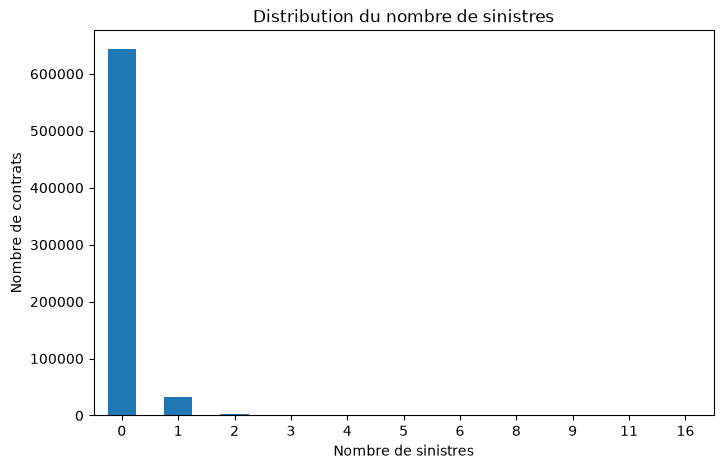

In [15]:
# Distribution du nombre de sinistres
plt.figure(figsize=(8,5))

freq["ClaimNb"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Nombre de sinistres")
plt.ylabel("Nombre de contrats")
plt.title("Distribution du nombre de sinistres")
plt.xticks(rotation=0)

plt.show()

In [16]:
# Frequence annuelle de sinistres. 
total_claims = freq["ClaimNb"].sum()
total_exposure = freq["Exposure"].sum()

frequence_globale = total_claims / total_exposure

print("Nombre total de sinistres :", total_claims)
print("Exposition totale :", total_exposure)
print("Fréquence annuelle globale :", frequence_globale) 

Nombre total de sinistres : 36102
Exposition totale : 358499.44546217704
Fréquence annuelle globale : 0.10070308464063966


In [17]:
print(
    f"La fréquence annuelle globale est de "
    f"{frequence_globale:.4f} sinistre par année d'exposition."
)

La fréquence annuelle globale est de 0.1007 sinistre par année d'exposition.


In [18]:
freq["Exposure"].describe() 

count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64

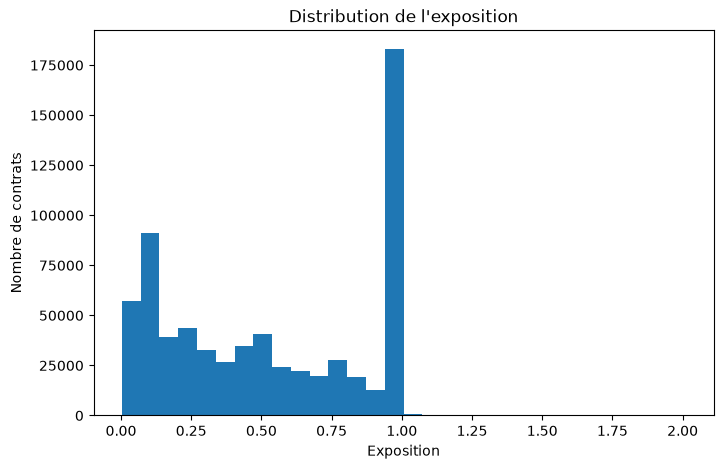

In [ ]:
# Distribution de l'exposition
plt.figure(figsize=(8,5))

plt.hist(freq["Exposure"], bins=30)

plt.xlabel("Exposition")
plt.ylabel("Nombre de contrats")
plt.title("Distribution de l'exposition")

plt.show() 

In [20]:
freq["ExposureGroup"] = pd.cut(
    freq["Exposure"],
    bins=[0, 0.25, 0.5, 0.75, 1.0],
    include_lowest=True
) 

analyse_exposure = freq.groupby("ExposureGroup", observed=True).agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_exposure["frequence"] = (
    analyse_exposure["sinistres"]
    / analyse_exposure["exposition"]
)

analyse_exposure

,contrats,sinistres,exposition,frequence
ExposureGroup,,,,
"(-0.001, 0.25]",222812,7131,24964.765462,0.285643
"(0.25, 0.5]",131302,6481,51388.740000,0.126117
"(0.5, 0.75]",92494,5968,58574.590000,0.101887
"(0.75, 1.0]",230181,16468,222208.010000,0.074111


In [22]:
freq["DrivAge"].describe()

count    678013.000000
mean         45.499122
std          14.137444
min          18.000000
25%          34.000000
50%          44.000000
75%          55.000000
max         100.000000
Name: DrivAge, dtype: float64

In [23]:
print("Âge minimum :", freq["DrivAge"].min())
print("Âge maximum :", freq["DrivAge"].max())
print("Nombre de valeurs différentes :", freq["DrivAge"].nunique())

Âge minimum : 18
Âge maximum : 100
Nombre de valeurs différentes : 83


In [24]:
# Regroupons les conducteurs par age.
bins_age = [17, 24, 29, 39, 49, 59, 69, np.inf]

labels_age = [
    "18-24",
    "25-29",
    "30-39",
    "40-49",
    "50-59",
    "60-69",
    "70+"
]

freq["AgeGroup"] = pd.cut(
    freq["DrivAge"],
    bins=bins_age,
    labels=labels_age
) 

In [25]:
# Calcul de la frequence de sinistres pour chaque groupe d'age 
analyse_age = freq.groupby("AgeGroup", observed=True).agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_age["frequence"] = (
    analyse_age["sinistres"]
    / analyse_age["exposition"]
)

analyse_age 

,contrats,sinistres,exposition,frequence
AgeGroup,,,,
18-24,30198,2364,12489.161085,0.189284
25-29,58807,2899,25785.260579,0.112429
30-39,168564,7350,82358.128465,0.089244
40-49,165702,9041,87685.666053,0.103107
50-59,142600,7816,79910.648453,0.097809
60-69,67812,3722,40089.861786,0.092841
70+,44330,2910,30180.719041,0.096419


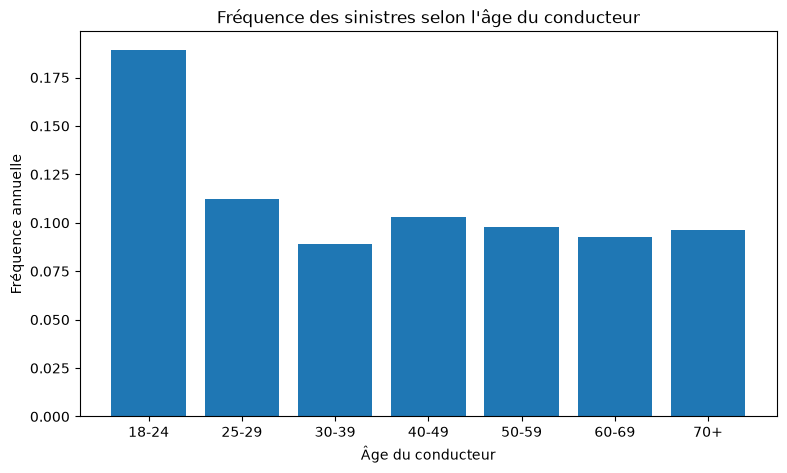

In [26]:
plt.figure(figsize=(9,5))

plt.bar(
    analyse_age.index.astype(str),
    analyse_age["frequence"]
)

plt.xlabel("Âge du conducteur")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon l'âge du conducteur")

plt.show() 

On observe que les jeunes conducteurs presentent une frequence de sinistres nettement plus elevee que les conducteurs plus ages.

La fréquence élevée des jeunes conducteurs vient-elle réellement de leur âge, ou certaines autres caractéristiques expliquent-elles une partie de cette différence ?


In [28]:
freq["VehAge"].describe() 
print("Âge minimum du véhicule :", freq["VehAge"].min())
print("Âge maximum du véhicule :", freq["VehAge"].max())
print("Nombre de valeurs différentes :", freq["VehAge"].nunique())

Âge minimum du véhicule : 0
Âge maximum du véhicule : 100
Nombre de valeurs différentes : 78


In [29]:
bins_vehage = [-1, 2, 5, 10, 15, 20, np.inf]

labels_vehage = [
    "0-2",
    "3-5",
    "6-10",
    "11-15",
    "16-20",
    "21+"
]

freq["VehAgeGroup"] = pd.cut(
    freq["VehAge"],
    bins=bins_vehage,
    labels=labels_vehage
) 

In [30]:
analyse_vehage = freq.groupby(
    "VehAgeGroup",
    observed=True
).agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_vehage["frequence"] = (
    analyse_vehage["sinistres"]
    / analyse_vehage["exposition"]
)

analyse_vehage 

,contrats,sinistres,exposition,frequence
VehAgeGroup,,,,
0-2,188147,10904,79176.055347,0.137718
3-5,132490,6743,72040.123776,0.093601
6-10,171594,9846,99008.916360,0.099446
11-15,134063,6648,77990.975407,0.085241
16-20,43397,1685,25136.158607,0.067035
21+,8322,276,5147.215965,0.053621


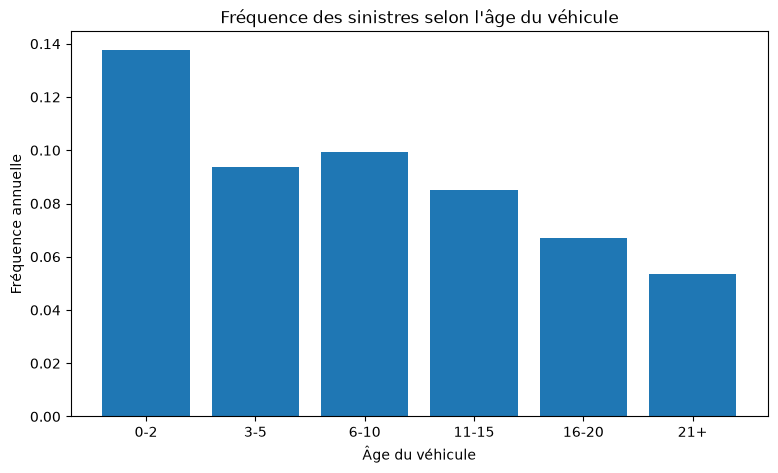

In [31]:
plt.figure(figsize=(9,5))

plt.bar(
    analyse_vehage.index.astype(str),
    analyse_vehage["frequence"]
)

plt.xlabel("Âge du véhicule")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon l'âge du véhicule")

plt.show() 

Plus le  vehicule est ancien, plus la frequence observee diminue.

In [32]:
freq["VehPower"].describe()
print("Puissance minimale :", freq["VehPower"].min())
print("Puissance maximale :", freq["VehPower"].max())
print("Nombre de valeurs différentes :", freq["VehPower"].nunique())

Puissance minimale : 4
Puissance maximale : 15
Nombre de valeurs différentes : 12


In [33]:
freq["VehPower"].value_counts().sort_index()

VehPower
4     115349
5     124821
6     148976
7     145401
8      46956
9      30085
10     31354
11     18352
12      8214
13      3229
14      2350
15      2926
Name: count, dtype: int64

In [34]:
analyse_power = freq.groupby("VehPower").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_power["frequence"] = (
    analyse_power["sinistres"]
    / analyse_power["exposition"]
)

analyse_power

,contrats,sinistres,exposition,frequence
VehPower,,,,
4,115349,5699,60073.637304,0.094867
5,124821,7278,68173.348821,0.106757
6,148976,8381,82524.210172,0.101558
7,145401,7627,77950.456700,0.097844
8,46956,1922,22684.616305,0.084727
9,30085,1754,15348.213656,0.114280
10,31354,1789,15375.010824,0.116358
11,18352,897,8497.778452,0.105557
12,8214,359,3792.038343,0.094672


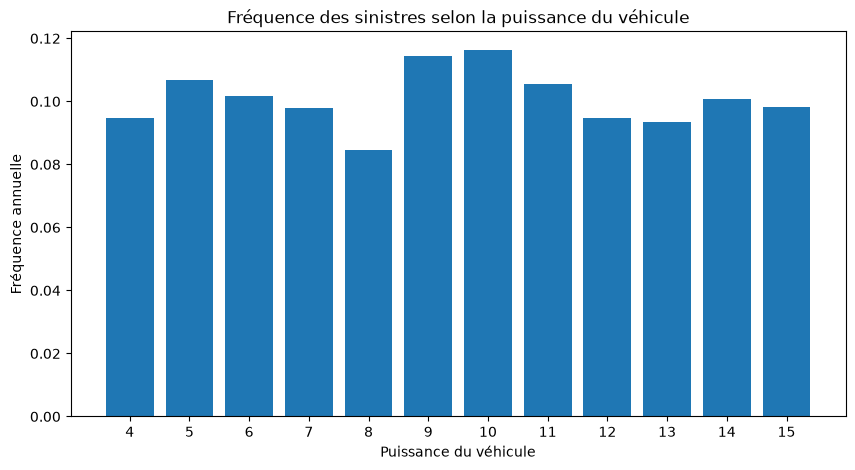

In [35]:
plt.figure(figsize=(10,5))

plt.bar(
    analyse_power.index.astype(str),
    analyse_power["frequence"]
)

plt.xlabel("Puissance du véhicule")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon la puissance du véhicule")

plt.show()

In [38]:
freq["BonusMalus"].describe()


count    678013.000000
mean         59.761502
std          15.636658
min          50.000000
25%          50.000000
50%          50.000000
75%          64.000000
max         230.000000
Name: BonusMalus, dtype: float64

In [39]:
print("Bonus-Malus minimal :", freq["BonusMalus"].min())
print("Bonus-Malus maximal :", freq["BonusMalus"].max())
print("Nombre de valeurs différentes :", freq["BonusMalus"].nunique()) 

Bonus-Malus minimal : 50
Bonus-Malus maximal : 230
Nombre de valeurs différentes : 115


In [40]:
freq["BonusMalus"].value_counts().sort_index() 

BonusMalus
50     384156
51      15869
52       4770
53       3351
54      17360
        ...  
198         2
208         1
218         1
228         1
230         1
Name: count, Length: 115, dtype: int64

In [41]:
analyse_bm = freq.groupby("BonusMalus").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_bm["frequence"] = (
    analyse_bm["sinistres"] / analyse_bm["exposition"]
)

analyse_bm

,contrats,sinistres,exposition,frequence
BonusMalus,,,,
50,384156,18056,225233.130902,0.080166
51,15869,540,8358.225595,0.064607
52,4770,315,2725.955217,0.115556
53,3351,198,1640.110809,0.120724
54,17360,610,8701.567408,0.070102
...,...,...,...,...
198,2,0,0.600000,0.000000
208,1,1,0.250000,4.000000
218,1,0,0.050000,0.000000


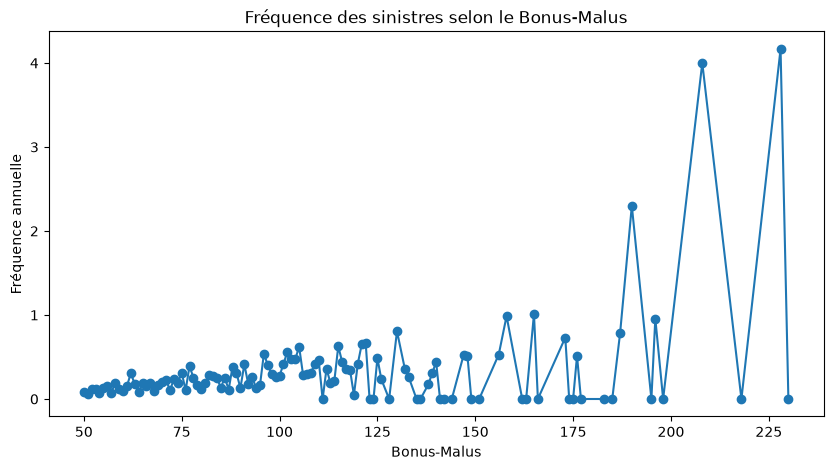

In [42]:
plt.figure(figsize=(10,5))

plt.plot(
    analyse_bm.index,
    analyse_bm["frequence"],
    marker="o"
)

plt.xlabel("Bonus-Malus")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon le Bonus-Malus")

plt.show()

In [43]:
bins_bm = [0, 50, 60, 70, 80, 90, 100, 110, 120, 140, np.inf]

labels_bm = [
    "≤50",
    "51-60",
    "61-70",
    "71-80",
    "81-90",
    "91-100",
    "101-110",
    "111-120",
    "121-140",
    "141+"
]

freq["BonusMalusGroup"] = pd.cut(
    freq["BonusMalus"],
    bins=bins_bm,
    labels=labels_bm
)

In [44]:
analyse_bm_group = freq.groupby("BonusMalusGroup", observed=True).agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_bm_group["frequence"] = (
    analyse_bm_group["sinistres"]
    / analyse_bm_group["exposition"]
)

analyse_bm_group

,contrats,sinistres,exposition,frequence
BonusMalusGroup,,,,
≤50,384156,18056,225233.130902,0.080166
51-60,94446,4553,47985.497013,0.094883
61-70,56929,3671,26497.713499,0.138540
71-80,61826,3386,26567.633294,0.127448
81-90,35725,2130,15247.759478,0.139693
91-100,37137,2964,13396.392272,0.221254
101-110,1989,294,921.093091,0.319186
111-120,3565,579,1651.909912,0.350503
121-140,1832,371,812.377703,0.456684


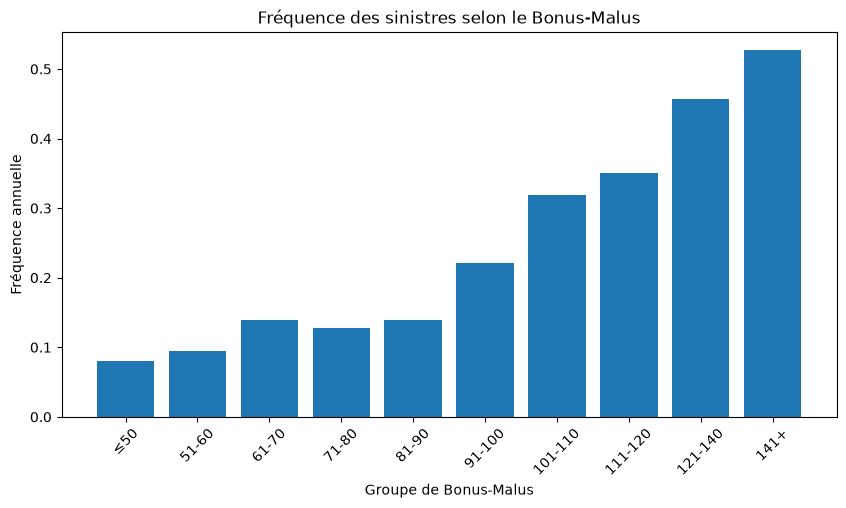

In [45]:
plt.figure(figsize=(10,5))

plt.bar(
    analyse_bm_group.index.astype(str),
    analyse_bm_group["frequence"]
)

plt.xlabel("Groupe de Bonus-Malus")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon le Bonus-Malus")

plt.xticks(rotation=45)
plt.show()

In [46]:
freq["Density"].describe()

count    678013.000000
mean       1792.422405
std        3958.646564
min           1.000000
25%          92.000000
50%         393.000000
75%        1658.000000
max       27000.000000
Name: Density, dtype: float64

In [47]:
print("Densité minimale :", freq["Density"].min())
print("Densité maximale :", freq["Density"].max())
print("Nombre de valeurs différentes :", freq["Density"].nunique())

Densité minimale : 1
Densité maximale : 27000
Nombre de valeurs différentes : 1607


In [48]:
freq["Density"].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
)

0.00        1.0
0.25       92.0
0.50      393.0
0.75     1658.0
0.90     4128.0
0.95     7313.0
0.99    27000.0
1.00    27000.0
Name: Density, dtype: float64

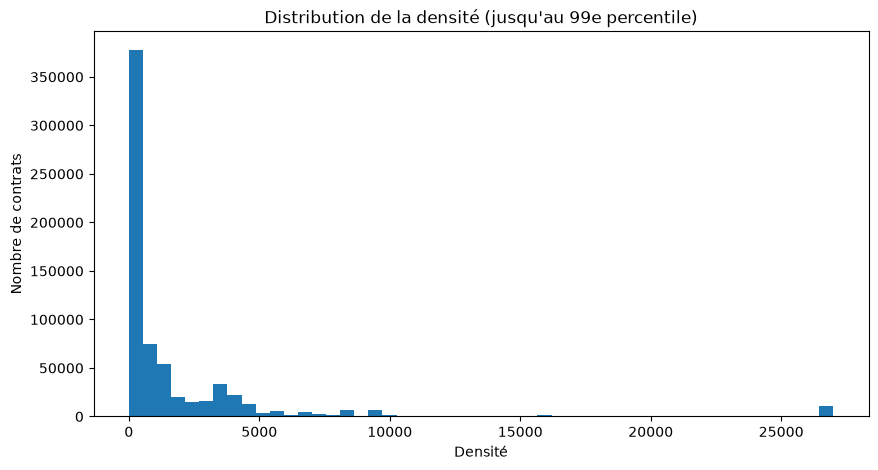

In [49]:
p99 = freq["Density"].quantile(0.99)

plt.figure(figsize=(10,5))

plt.hist(
    freq.loc[freq["Density"] <= p99, "Density"],
    bins=50
)

plt.xlabel("Densité")
plt.ylabel("Nombre de contrats")
plt.title("Distribution de la densité (jusqu'au 99e percentile)")

plt.show()

In [50]:
freq["DensityGroup"] = pd.qcut(
    freq["Density"],
    q=5,
    duplicates="drop"
)

In [51]:
analyse_density = freq.groupby(
    "DensityGroup",
    observed=True
).agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_density["frequence"] = (
    analyse_density["sinistres"]
    / analyse_density["exposition"]
)

analyse_density

,contrats,sinistres,exposition,frequence
DensityGroup,,,,
"(0.999, 67.0]",137340,6753,81409.009565,0.082952
"(67.0, 214.0]",134178,6743,74104.379569,0.090993
"(214.0, 716.0]",135398,7091,72041.131585,0.098430
"(716.0, 2715.0]",137845,7855,69486.203925,0.113044
"(2715.0, 27000.0]",133252,7660,61458.720818,0.124637


In [52]:
freq["VehGas"].value_counts() 

VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64

In [53]:
analyse_gas = freq.groupby("VehGas").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_gas["frequence"] = (
    analyse_gas["sinistres"]
    / analyse_gas["exposition"]
)

analyse_gas

,contrats,sinistres,exposition,frequence
VehGas,,,,
Diesel,332136,16648,170660.893126,0.097550
Regular,345877,19454,187838.552336,0.103568


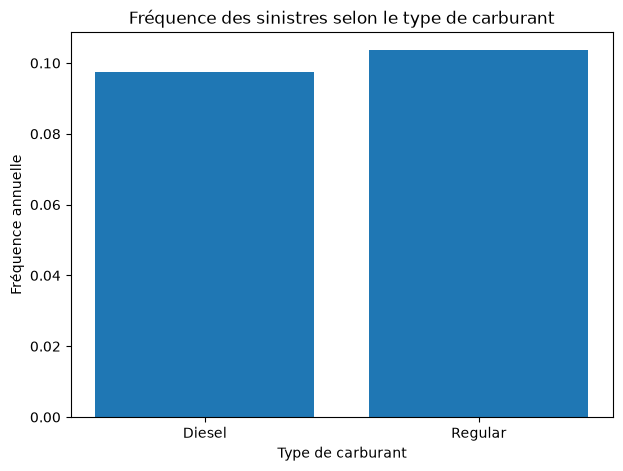

In [54]:
plt.figure(figsize=(7,5))

plt.bar(
    analyse_gas.index,
    analyse_gas["frequence"]
)

plt.xlabel("Type de carburant")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon le type de carburant")

plt.show() 

In [55]:
freq["VehBrand"].value_counts()

VehBrand
B12    166024
B1     162736
B2     159861
B3      53395
B5      34753
B6      28548
B4      25179
B10     17707
B11     13585
B13     12178
B14      4047
Name: count, dtype: int64

In [56]:
analyse_brand = freq.groupby("VehBrand").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_brand["frequence"] = (
    analyse_brand["sinistres"]
    / analyse_brand["exposition"]
)

analyse_brand 

,contrats,sinistres,exposition,frequence
VehBrand,,,,
B1,162736,8677,95351.059578,0.091001
B10,17707,858,9496.014123,0.090354
B11,13585,721,6887.817279,0.104678
B12,166024,8859,64808.608718,0.136695
B13,12178,649,6772.032216,0.095835
B14,4047,166,2274.467743,0.072984
B2,159861,8560,94864.057101,0.090234
B3,53395,2818,28592.876331,0.098556
B4,25179,1312,13775.496080,0.095242


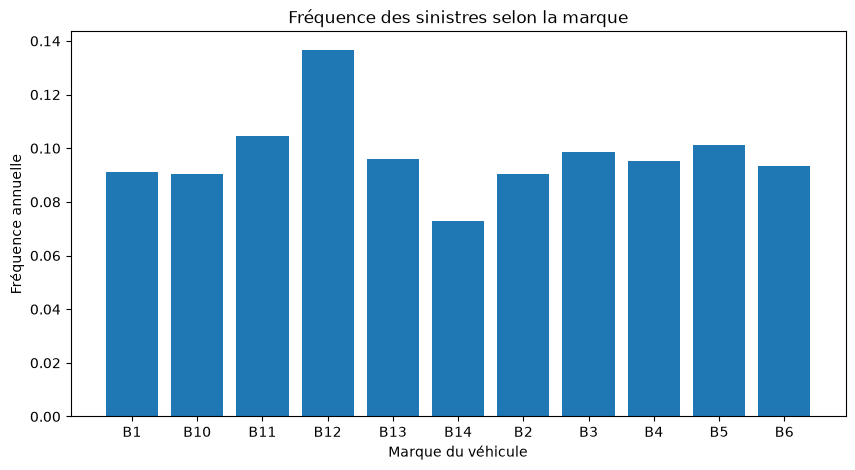

In [57]:
plt.figure(figsize=(10,5))

plt.bar(
    analyse_brand.index,
    analyse_brand["frequence"]
)

plt.xlabel("Marque du véhicule")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon la marque")

plt.show()

In [58]:
freq["Area"].value_counts().sort_index()

Area
A    103957
B     75459
C    191880
D    151596
E    137167
F     17954
Name: count, dtype: int64

In [59]:
analyse_area = freq.groupby("Area").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_area["frequence"] = (
    analyse_area["sinistres"]
    / analyse_area["exposition"]
)

analyse_area

,contrats,sinistres,exposition,frequence
Area,,,,
A,103957,5063,61969.377712,0.081702
B,75459,3800,43012.323931,0.088347
C,191880,9875,104449.003784,0.094544
D,151596,8428,77120.191692,0.109284
E,137167,7805,63819.314270,0.122298
F,17954,1131,8129.234074,0.139127


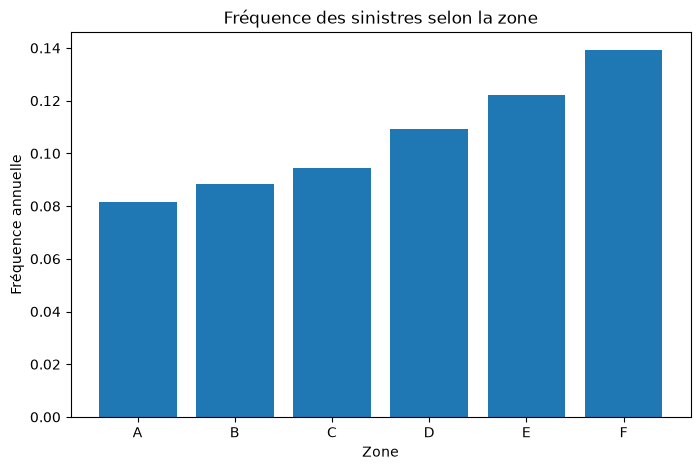

In [60]:
plt.figure(figsize=(8,5))

plt.bar(
    analyse_area.index,
    analyse_area["frequence"]
)

plt.xlabel("Zone")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon la zone")

plt.show()

In [61]:
freq["Region"].value_counts().sort_index()

Region
Alsace                           2200
Aquitaine                       31329
Auvergne                         5287
Basse-Normandie                 10893
Bourgogne                       10492
Bretagne                        42122
Centre                         160601
Champagne-Ardenne                3026
Corse                            4516
Franche-Comte                    1326
Haute-Normandie                  8784
Ile-de-France                   69791
Languedoc-Roussillon            35805
Limousin                         4567
Midi-Pyrenees                   17141
Nord-Pas-de-Calais              40275
Pays-de-la-Loire                38751
Picardie                         7994
Poitou-Charentes                19046
Provence-Alpes-Cotes-D'Azur     79315
Rhone-Alpes                     84752
Name: count, dtype: int64

In [62]:
analyse_region = freq.groupby("Region").agg(
    contrats=("IDpol", "count"),
    sinistres=("ClaimNb", "sum"),
    exposition=("Exposure", "sum")
)

analyse_region["frequence"] = (
    analyse_region["sinistres"]
    / analyse_region["exposition"]
)

analyse_region

,contrats,sinistres,exposition,frequence
Region,,,,
Alsace,2200,133,1209.115823,0.109998
Aquitaine,31329,1348,14322.166692,0.094120
Auvergne,5287,189,2322.884229,0.081364
Basse-Normandie,10893,633,6657.901142,0.095075
Bourgogne,10492,511,5025.358609,0.101684
Bretagne,42122,2702,27753.463675,0.097357
Centre,160601,9204,102712.903386,0.089609
Champagne-Ardenne,3026,160,1205.831509,0.132689
Corse,4516,247,1765.935399,0.139869


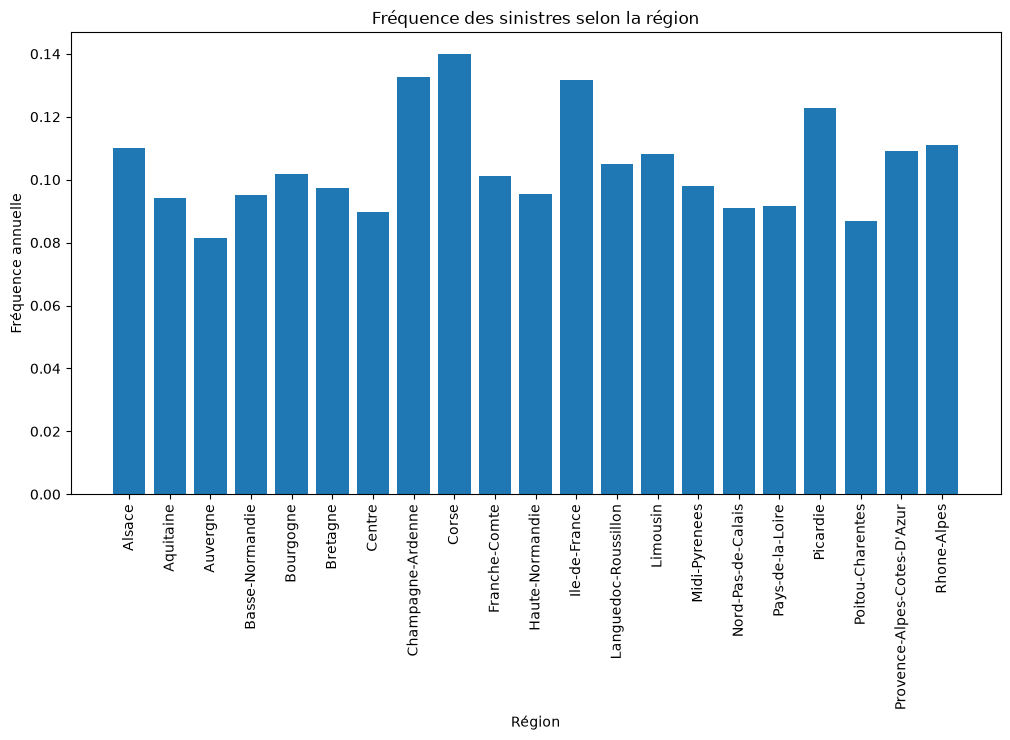

In [68]:
plt.figure(figsize=(12,6))

plt.bar(
    analyse_region.index,
    analyse_region["frequence"]
)

plt.xlabel("Région")
plt.ylabel("Fréquence annuelle")
plt.title("Fréquence des sinistres selon la région")

plt.xticks(rotation=90)

plt.show() 

## Variables quantitatives

| Variable | Ce que nous avons observé |
|---|---|
| `DrivAge` | relation non linéaire |
| `VehAge` | tendance globalement décroissante |
| `VehPower` | relation irrégulière |
| `BonusMalus` | **relation fortement croissante** |
| `Density` | **relation croissante** |

## Variables qualitatives

| Variable | Observation |
|---|---|
| `VehGas` | différence faible |
| `VehBrand` | différences entre marques |
| `Area` | **différence assez nette** |
| `Region` | différences importantes |

# Modele de Poisson

In [69]:
# Importation des bibliotheques
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [70]:
modele_glm = smf.glm(
    formula="""
    ClaimNb ~ DrivAge + VehAge + VehPower + BonusMalus + Density
              + C(VehBrand) + C(VehGas) + C(Area) + C(Region)
    """,
    data=freq,
    family=sm.families.Poisson(),
    offset=np.log(freq["Exposure"])
) 

In [71]:
resultats_glm = modele_glm.fit() 

In [72]:
print(resultats_glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677971
Model Family:                 Poisson   Df Model:                           41
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4331e+05
Date:                Fri, 30 Oct 2026   Deviance:                   2.1730e+05
Time:                        12:39:57   Pearson chi2:                 1.79e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01053
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

Ce que nous avons appris avec ce premier GLM
Notre modèle nous donne déjà plusieurs enseignements :
Variables fortement associées à la fréquence
BonusMalus, VehAge, DrivAge, Area, certaines marques, etc.
Certaines relations semblent simples
Par exemple VehAge.
Certaines semblent mal représentées par une relation linéaire
Notamment DrivAge, et probablement Density et VehPower.
Et surtout :

**Poisson présente une surdispersion importante**

avec un ratio Pearson/df d'environ :**2.64**

## Amelioration de notre modele de reference

In [73]:
modele_nb = smf.glm(
    formula="""
    ClaimNb ~ DrivAge + VehAge + VehPower + BonusMalus + Density
              + C(VehBrand) + C(VehGas) + C(Area) + C(Region)
    """,
    data=freq,
    family=sm.families.NegativeBinomial(),
    offset=np.log(freq["Exposure"])
)

c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


In [75]:
resultats_nb = modele_nb.fit() 

In [76]:
print(resultats_nb.summary()) 

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677971
Model Family:        NegativeBinomial   Df Model:                           41
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4289e+05
Date:                Fri, 30 Oct 2026   Deviance:                   1.8930e+05
Time:                        18:20:34   Pearson chi2:                 1.73e+06
No. Iterations:                     8   Pseudo R-squ. (CS):           0.009921
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [77]:
print("AIC Poisson :", resultats_glm.aic)
print("AIC Binomiale négative :", resultats_nb.aic) 

AIC Poisson : 286708.00683131814
AIC Binomiale négative : 285871.03883441363


In [78]:
from sklearn.model_selection import train_test_split

# 1. Sélection des variables nécessaires au projet
colonnes = [
    "IDpol",
    "ClaimNb",
    "Exposure",
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "VehBrand",
    "VehGas",
    "Area",
    "Density",
    "Region"
]

donnees = freq[colonnes].copy()

# 2. Vérifications fondamentales
assert donnees["IDpol"].is_unique
assert (donnees["Exposure"] > 0).all()
assert (donnees["ClaimNb"] >= 0).all()

# 3. Première séparation : 85 % développement, 15 % test
developpement, test = train_test_split(
    donnees,
    test_size=0.15,
    random_state=42,
    stratify=donnees["ClaimNb"] > 0
)

# 4. Deuxième séparation : 70 % apprentissage, 15 % validation
apprentissage, validation = train_test_split(
    developpement,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=developpement["ClaimNb"] > 0
)

# 5. Vérification des dimensions
print("Apprentissage :", apprentissage.shape)
print("Validation :", validation.shape)
print("Test :", test.shape) 

Apprentissage : (474609, 12)
Validation : (101702, 12)
Test : (101702, 12)


In [79]:
def bilan_echantillon(nom, df):
    return {
        "Echantillon": nom,
        "Nombre de contrats": len(df),
        "Contrats sans sinistre (%)": 100 * (df["ClaimNb"] == 0).mean(),
        "Contrats avec sinistre (%)": 100 * (df["ClaimNb"] > 0).mean(),
        "Contrats avec 2 sinistres ou plus (%)": 100 * (df["ClaimNb"] >= 2).mean()
    }


bilan_repartition = pd.DataFrame([
    bilan_echantillon("Apprentissage", apprentissage),
    bilan_echantillon("Validation", validation),
    bilan_echantillon("Test", test)
])

display(bilan_repartition.round(3))

,Echantillon,Nombre de contrats,Contrats sans sinistre (%),Contrats avec sinistre (%),Contrats avec 2 sinistres ou plus (%)
0,Apprentissage,474609,94.976,5.024,0.275
1,Validation,101702,94.976,5.024,0.289
2,Test,101702,94.976,5.024,0.279


In [80]:
def bilan_actuariel(nom, df):
    return {
        "Echantillon": nom,
        "Nombre de contrats": len(df),
        "Sinistres totaux": df["ClaimNb"].sum(),
        "Exposition totale": df["Exposure"].sum(),
        "Exposition moyenne": df["Exposure"].mean(),
        "Fréquence annuelle": (
            df["ClaimNb"].sum() / df["Exposure"].sum()
        )
    }


bilan_frequence = pd.DataFrame([
    bilan_actuariel("Apprentissage", apprentissage),
    bilan_actuariel("Validation", validation),
    bilan_actuariel("Test", test)
])

display(bilan_frequence.round(4))

,Echantillon,Nombre de contrats,Sinistres totaux,Exposition totale,Exposition moyenne,Fréquence annuelle
0,Apprentissage,474609,25259,250842.2779,0.5285,0.1007
1,Validation,101702,5417,53897.2829,0.5300,0.1005
2,Test,101702,5426,53759.8846,0.5286,0.1009


In [81]:
assert set(apprentissage["IDpol"]).isdisjoint(
    set(validation["IDpol"])
)

assert set(apprentissage["IDpol"]).isdisjoint(
    set(test["IDpol"])
)

assert set(validation["IDpol"]).isdisjoint(
    set(test["IDpol"])
)

print("Aucun chevauchement entre les trois échantillons.")

Aucun chevauchement entre les trois échantillons.


Construisons le modele sur la base d'apprentissage

In [82]:
formule_frequence = """
ClaimNb ~ DrivAge + VehAge + VehPower + BonusMalus + Density
          + C(VehBrand) + C(VehGas) + C(Area) + C(Region)
"""

modele_poisson = smf.glm(
    formula=formule_frequence,
    data=apprentissage,
    family=sm.families.Poisson(),
    offset=np.log(apprentissage["Exposure"])
)

resultat_poisson = modele_poisson.fit()

print(resultat_poisson.summary()) 

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               474609
Model:                            GLM   Df Residuals:                   474567
Model Family:                 Poisson   Df Model:                           41
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.0030e+05
Date:                Fri, 30 Oct 2026   Deviance:                   1.5208e+05
Time:                        19:22:54   Pearson chi2:                 1.27e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01050
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [83]:
from sklearn.metrics import mean_poisson_deviance

# Prédiction de la fréquence annuelle
lambda_validation = resultat_poisson.predict(validation)

# Nombre moyen de sinistres attendu compte tenu de l'exposition
mu_validation = validation["Exposure"] * lambda_validation

# Déviance de Poisson moyenne
deviance_validation = mean_poisson_deviance(
    validation["ClaimNb"],
    mu_validation
)

print(f"Déviance de Poisson moyenne : {deviance_validation:.6f}")

Déviance de Poisson moyenne : 0.321694


In [84]:

# 1. Estimation de la fréquence globale sur l'apprentissage
lambda_baseline = (
    apprentissage["ClaimNb"].sum()
    / apprentissage["Exposure"].sum()
)

# 2. Prédiction du nombre de sinistres sur la validation
mu_baseline = validation["Exposure"] * lambda_baseline

# 3. Calcul de la déviance moyenne du modèle de référence
deviance_baseline = mean_poisson_deviance(
    validation["ClaimNb"],
    mu_baseline
)

# 4. Comparaison avec notre modèle Poisson multivarié
deviance_poisson = mean_poisson_deviance(
    validation["ClaimNb"],
    mu_validation
)

# 5. Gain relatif de déviance
gain = 100 * (
    (deviance_baseline - deviance_poisson)
    / deviance_baseline
)

print(f"Fréquence globale de référence : {lambda_baseline:.6f}")
print(f"Déviance baseline : {deviance_baseline:.6f}")
print(f"Déviance Poisson : {deviance_poisson:.6f}")
print(f"Réduction de déviance : {gain:.2f} %") 

Fréquence globale de référence : 0.100697
Déviance baseline : 0.332423
Déviance Poisson : 0.321694
Réduction de déviance : 3.23 %


In [86]:
# Construction du modèle binomial négatif NB2
modele_nb = smf.negativebinomial(
    formula=formule_frequence,
    data=apprentissage,
    loglike_method="nb2",
    exposure=apprentissage["Exposure"]
)

# Estimation des paramètres par maximum de vraisemblance
resultat_nb = modele_nb.fit(
    method="bfgs",
    maxiter=200,
    disp=True
)

# Affichage des résultats
print(resultat_nb.summary())

# Vérification de la convergence
print("Convergence :", resultat_nb.mle_retvals.get("converged"))

# Paramètre de dispersion estimé
print("Alpha estimé :", resultat_nb.params["alpha"]) 

c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3384: RuntimeWarning: overflow encountered in exp
  alpha = np.exp(params[-1])
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3377: RuntimeWarning: invalid value encountered in subtract
  coeff = (gamma_ln(size+endog) - gamma_ln(endog+1) -
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3448: RuntimeWarning: overflow encountered in exp
  alpha = np.exp(params[-1])
c:\Users\TESLA ELE

         Current function value: nan
         Iterations: 0
         Function evaluations: 1
         Gradient evaluations: 1


c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3614: RuntimeWarning: divide by zero encountered in log
  np.log(prob) - (y - mu)/(a1+mu))
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3613: RuntimeWarning: invalid value encountered in add
  dalpha = da1 * (dgpart +
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3615: RuntimeWarning: invalid value encountered in subtract
  dada = (da2 * dalpha/da1 + da1**2 * (special.polygamma(1, a1+y) -
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3616: RuntimeWarning: divide by zero encountered in scalar divide
  special.polygamma(1, a1) + 1/a1 - 1/(a1 + mu) +
c:\Users\TESLA ELECTRONICS\anacondanew\Lib\site-packages\statsmodels\discrete\discrete_model.py:3615: RuntimeWarning: invalid value encountered in add
  dada = (da2 * dalpha/da1 + da1**2 * (special.p

                     NegativeBinomial Regression Results                      
Dep. Variable:                ClaimNb   No. Observations:               474609
Model:               NegativeBinomial   Df Residuals:                   474567
Method:                           MLE   Df Model:                           41
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                     nan
Time:                        19:38:00   Log-Likelihood:                    nan
converged:                      False   LL-Null:                   -1.0234e+05
Covariance Type:            nonrobust   LLR p-value:                       nan
                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                   -4.0291        nan        nan        nan         nan         nan
C(VehBrand)[T.B10]                       

In [87]:
# Vérification de l'estimation obtenue

print("Convergence :", resultat_nb.mle_retvals.get("converged"))
print("Log-vraisemblance :", resultat_nb.llf)

print("\nParamètres contenant des NaN :")
print(resultat_nb.params[resultat_nb.params.isna()])

print("\nParamètre alpha :")
print(resultat_nb.params.get("alpha")) 

Convergence : False
Log-vraisemblance : nan

Paramètres contenant des NaN :
Series([], dtype: float64)

Paramètre alpha :
inf


In [88]:
# Prédictions du modèle de Poisson sur l'apprentissage
mu_train = resultat_poisson.fittedvalues.to_numpy()

# Nombre de sinistres observés
y_train = apprentissage["ClaimNb"].to_numpy()

# Estimation initiale du paramètre de dispersion
alpha_initial = np.sum(
    ((y_train - mu_train)**2 - mu_train) / mu_train**2
) / resultat_poisson.df_resid

print("Alpha initial :", alpha_initial)

Alpha initial : 1562.4023585837929


In [90]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_poisson_deviance

# Variables numériques
variables_num = [
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "Density"
]

# Variables catégorielles
variables_cat = [
    "VehBrand",
    "VehGas",
    "Area",
    "Region"
]

# Variables explicatives
variables = variables_num + variables_cat

# Matrices explicatives
X_train = apprentissage[variables]
X_validation = validation[variables]

# Variable cible : fréquence annualisée
y_train = apprentissage["ClaimNb"] / apprentissage["Exposure"]

# Poids associés aux contrats
poids_train = apprentissage["Exposure"] 

In [91]:
preprocesseur = ColumnTransformer(
    transformers=[
        ("categoriel", OneHotEncoder(handle_unknown="ignore"), variables_cat),
        ("numerique", "passthrough", variables_num)
    ]
)

In [92]:
modele_rf = Pipeline(
    steps=[
        ("preparation", preprocesseur),
        ("foret", RandomForestRegressor(
            n_estimators=100,
            criterion="poisson",
            max_depth=16,
            min_samples_leaf=100,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entraînement
modele_rf.fit(
    X_train,
    y_train,
    foret__sample_weight=poids_train
)

print("Entraînement de la Random Forest terminé.") 

Entraînement de la Random Forest terminé.


In [93]:
# Prédiction de la fréquence annuelle
lambda_rf_validation = modele_rf.predict(X_validation)

# Protection numérique : la déviance exige des prédictions strictement positives
lambda_rf_validation = np.maximum(
    lambda_rf_validation,
    1e-8
)

# Nombre moyen de sinistres attendu
mu_rf_validation = (
    validation["Exposure"].to_numpy()
    * lambda_rf_validation
)

# Déviance moyenne sur la validation
deviance_rf = mean_poisson_deviance(
    validation["ClaimNb"],
    mu_rf_validation
)

print(f"Déviance Poisson GLM : {deviance_validation:.6f}")
print(f"Déviance Random Forest : {deviance_rf:.6f}") 

Déviance Poisson GLM : 0.321694
Déviance Random Forest : 0.304239


In [94]:
variables_num = [
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "Density"
]

variables_cat = [
    "VehBrand",
    "VehGas",
    "Area",
    "Region"
]

variables = variables_num + variables_cat

X_train_xgb = pd.get_dummies(
    apprentissage[variables],
    columns=variables_cat,
    drop_first=False,
    dtype=float
)

X_validation_xgb = pd.get_dummies(
    validation[variables],
    columns=variables_cat,
    drop_first=False,
    dtype=float
)

# Garantir exactement les mêmes colonnes
X_validation_xgb = X_validation_xgb.reindex(
    columns=X_train_xgb.columns,
    fill_value=0
)

y_train_xgb = apprentissage["ClaimNb"]

exposure_train_xgb = apprentissage["Exposure"]

print("X_train :", X_train_xgb.shape)
print("X_validation :", X_validation_xgb.shape) 

X_train : (474609, 45)
X_validation : (101702, 45)


In [ ]:
#pip install  xgboost  

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 5.6 MB/s eta 0:00:09
   - -------------------------------------- 2.4/48.9 MB 5.7 MB/s eta 0:00:09
   --- ------------------------------------ 3.9/48.9 MB 6.6 MB/s eta 0:00:07
   ---- ----------------------------------- 5.5/48.9 MB 7.1 MB/s eta 0:00:07
   ------ --------------------------------- 7.6/48.9 MB 7.6 MB/s eta 0:00:06
   ------- -------------------------------- 9.7/48.9 MB 7.9 MB/s eta 0:00:05
   --------- ------------------------------ 11.3/48.9 MB 8.1 MB/s eta 0:00:05
   ---------- ----------------------------- 13.4/48.9 MB 8.1 MB/s eta 0:00:05
   ----------- ---------------------------- 14.7/48.9 MB 8.0 MB/s eta 0:00:05
   ------------- -------------------------- 16.8/48.9 MB 8.1 MB/s eta 0:00:04
   --------------- ------------------------ 19.1/48.9 MB 8.4 MB/s eta 0:00:04
   ----------------- ---------------------- 21.2/48.9 MB 8.5 MB/s eta 0:00:04


In [97]:
import xgboost as xgb 

In [98]:
modele_xgb = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
) 

In [99]:
modele_xgb.fit(
    X_train_xgb,
    y_train_xgb,
    sample_weight=exposure_train_xgb,
    verbose=False
)

print("Entraînement XGBoost terminé.")

Entraînement XGBoost terminé.


In [100]:
mu_xgb_validation = modele_xgb.predict(
    X_validation_xgb
)

mu_xgb_validation = np.maximum(
    mu_xgb_validation,
    1e-8
)

deviance_xgb = mean_poisson_deviance(
    validation["ClaimNb"],
    mu_xgb_validation
)

print(f"Déviance GLM Poisson : {deviance_validation:.6f}")
print(f"Déviance Random Forest : {deviance_rf:.6f}")
print(f"Déviance XGBoost : {deviance_xgb:.6f}") 

Déviance GLM Poisson : 0.321694
Déviance Random Forest : 0.304239
Déviance XGBoost : 0.304384


In [101]:
importance_xgb = modele_xgb.get_booster().get_score(
    importance_type="gain"
)

importance_xgb

{'VehPower': 2.4799604415893555,
 'VehAge': 3.792797088623047,
 'DrivAge': 3.590581178665161,
 'BonusMalus': 11.648087501525879,
 'Density': 1.8708858489990234,
 'VehBrand_B1': 1.7275522947311401,
 'VehBrand_B10': 1.7047793865203857,
 'VehBrand_B11': 2.034794330596924,
 'VehBrand_B12': 8.325369834899902,
 'VehBrand_B13': 2.399250030517578,
 'VehBrand_B14': 1.4201029539108276,
 'VehBrand_B2': 1.6416254043579102,
 'VehBrand_B3': 1.6433405876159668,
 'VehBrand_B4': 1.7548996210098267,
 'VehBrand_B5': 1.8925559520721436,
 'VehBrand_B6': 1.7113343477249146,
 'VehGas_Diesel': 3.460822820663452,
 'VehGas_Regular': 2.5411503314971924,
 'Area_A': 1.7186020612716675,
 'Area_B': 1.613136887550354,
 'Area_C': 1.6801531314849854,
 'Area_D': 1.7647178173065186,
 'Area_E': 1.8825925588607788,
 'Area_F': 2.1455512046813965,
 'Region_Alsace': 1.0236608982086182,
 'Region_Aquitaine': 1.8482660055160522,
 'Region_Auvergne': 1.5082443952560425,
 'Region_Basse-Normandie': 1.956789493560791,
 'Region_Bourgo

In [102]:
importance_xgb_df = (
    pd.DataFrame(
        importance_xgb.items(),
        columns=["Variable", "Gain"]
    )
    .sort_values("Gain", ascending=False)
)

importance_xgb_df 

,Variable,Gain
3,BonusMalus,11.648088
8,VehBrand_B12,8.325370
36,Region_Languedoc-Roussillon,4.005825
1,VehAge,3.792797
2,DrivAge,3.590581
29,Region_Bretagne,3.538274
16,VehGas_Diesel,3.460823
38,Region_Midi-Pyrenees,2.946655
30,Region_Centre,2.749869
39,Region_Nord-Pas-de-Calais,2.587265


In [104]:
def regrouper_variable(variable):
    if variable in variables_num:
        return variable
    
    for var in variables_cat:
        if variable.startswith(var + "_"):
            return var
    
    return variable


importance_xgb_df["Variable_globale"] = (
    importance_xgb_df["Variable"]
    .apply(regrouper_variable)
)

In [105]:
importance_globale_xgb = (
    importance_xgb_df
    .groupby("Variable_globale", as_index=False)["Gain"]
    .sum()
    .sort_values("Gain", ascending=False)
)

importance_globale_xgb

,Variable_globale,Gain
4,Region,42.394664
6,VehBrand,26.255605
1,BonusMalus,11.648088
0,Area,10.804754
7,VehGas,6.001973
5,VehAge,3.792797
3,DrivAge,3.590581
8,VehPower,2.479960
2,Density,1.870886


In [106]:
importance_globale_xgb["Importance"] = (
    importance_globale_xgb["Gain"]
    / importance_globale_xgb["Gain"].sum()
    * 100
)

In [107]:
importance_globale_xgb

,Variable_globale,Gain,Importance
4,Region,42.394664,38.951611
6,VehBrand,26.255605,24.123274
1,BonusMalus,11.648088,10.702096
0,Area,10.804754,9.927253
7,VehGas,6.001973,5.514527
5,VehAge,3.792797,3.484768
3,DrivAge,3.590581,3.298975
8,VehPower,2.479960,2.278552
2,Density,1.870886,1.718943


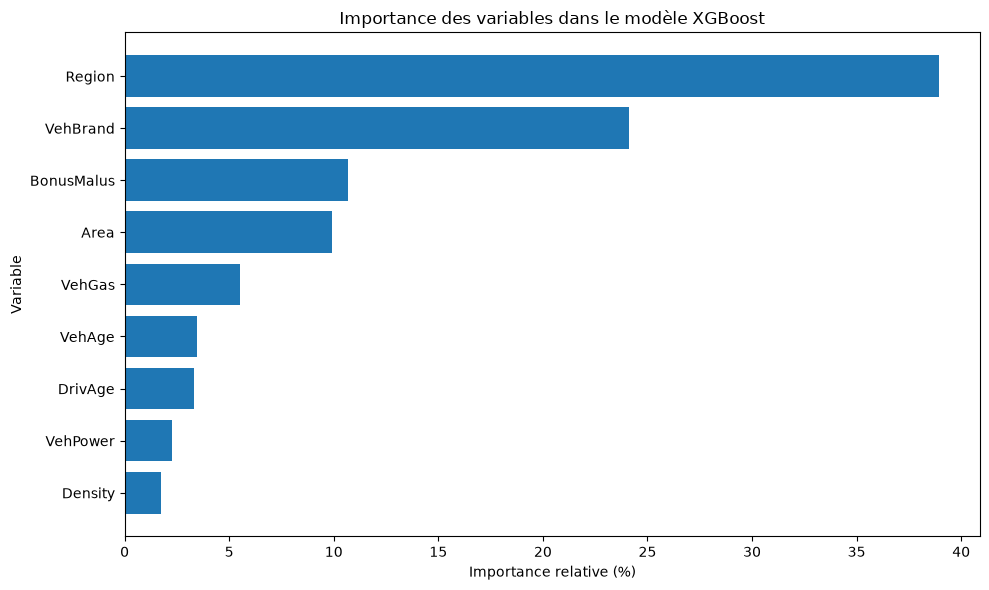

In [108]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_globale_xgb["Variable_globale"],
    importance_globale_xgb["Importance"]
)

plt.xlabel("Importance relative (%)")
plt.ylabel("Variable")
plt.title("Importance des variables dans le modèle XGBoost")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show() 

# Conclusion générale — Modélisation de la fréquence des sinistres automobiles

## 1. Synthèse de l'analyse exploratoire

L'étude a été menée à partir de la base `freMTPL2freq`, composée de **678 013 contrats d'assurance automobile**. Elle contient notamment le nombre de sinistres déclarés (`ClaimNb`), la durée d'exposition au risque (`Exposure`) ainsi que différentes caractéristiques relatives aux conducteurs, aux véhicules et à leur localisation géographique.

La base recense 36 102 sinistres pour une exposition totale d'environ 358 499 années-contrats. La fréquence annuelle globale du portefeuille est donc estimée à :


$$
\widehat{\lambda}
=
\frac{\displaystyle\sum_{i=1}^{n} N_i}
{\displaystyle\sum_{i=1}^{n} E_i}
\approx 0{,}1007,
$$
Cela correspond à environ **0,101 sinistre par année-contrat**.

L'analyse exploratoire a mis en évidence plusieurs relations intéressantes entre les caractéristiques des assurés et la fréquence observée des sinistres. En particulier :

- Le coefficient `BonusMalus` présente une relation fortement croissante avec la fréquence observée : les assurés ayant un coefficient élevé présentent globalement davantage de sinistres.
- L'âge du conducteur joue également un rôle important, les conducteurs les plus jeunes, notamment ceux âgés de 18 à 24 ans, présentant une fréquence plus élevée.
- La fréquence observée tend globalement à diminuer avec l'âge du véhicule.
- Des différences de fréquence apparaissent selon la zone géographique, la région, la marque et le type de carburant du véhicule.
- La densité de population présente également une association positive avec la fréquence observée dans les groupes étudiés.

Ces résultats constituent des observations descriptives. Ils ne permettent pas, à eux seuls, de conclure à des relations causales, car plusieurs caractéristiques peuvent être liées entre elles.

## 2. Comparaison des modèles prédictifs

L'objectif principal était de construire un modèle capable de prédire le nombre de sinistres en tenant compte de l'exposition au risque.

Pour garantir une évaluation cohérente, les données ont été réparties en trois ensembles : apprentissage (70 %), validation (15 %) et test (15 %). Les modèles ont été entraînés sur l'ensemble d'apprentissage et comparés sur le même ensemble de validation.

Trois approches ont été étudiées :

- **Modèle de référence (Baseline)** : estimation d'une fréquence annuelle globale, appliquée à l'ensemble des contrats.
- **GLM de Poisson** : modèle actuariel classique utilisant une fonction de lien logarithmique et un offset égal au logarithme de l'exposition.
- **Random Forest et XGBoost** : modèles de machine learning capables de prendre en compte des relations non linéaires et des interactions entre variables.

La métrique retenue pour comparer les prédictions est la déviance de Poisson moyenne. Une valeur plus faible traduit une meilleure qualité prédictive selon ce critère.

| Modèle | Déviance de validation |
|---|---:|
| Baseline | 0,332423 |
| GLM de Poisson | 0,321694 |
| Random Forest | 0,304239 |
| XGBoost | 0,304384 |

Les résultats montrent que le GLM de Poisson améliore la prédiction par rapport à la fréquence globale de référence, avec une réduction de la déviance d'environ 3,23 %.

Les deux modèles de machine learning obtiennent de meilleures performances sur l'ensemble de validation. Le Random Forest réduit la déviance d'environ 8,48 % par rapport au modèle de référence, tandis que XGBoost l'améliore d'environ 8,43 %.

Le Random Forest obtient la déviance la plus faible, mais l'écart avec XGBoost est extrêmement réduit. Les deux modèles présentent donc des performances prédictives pratiquement équivalentes sur cet échantillon.

Ces résultats suggèrent que les méthodes de machine learning par arbres permettent de mieux exploiter les relations complexes présentes dans les données que le modèle linéaire généralisé étudié.

## 3. Interprétation de l'importance des variables avec XGBoost

Une première analyse de l'importance des variables a été réalisée à partir de la mesure `gain` de XGBoost.

Après regroupement des différentes modalités des variables catégorielles, le classement obtenu est le suivant :

| Variable | Importance relative |
|---|---:|
| Region | 38,95 % |
| VehBrand | 24,12 % |
| BonusMalus | 10,70 % |
| Area | 9,93 % |
| VehGas | 5,51 % |
| VehAge | 3,48 % |
| DrivAge | 3,30 % |
| VehPower | 2,28 % |
| Density | 1,72 % |

La région et la marque du véhicule occupent les deux premières positions et représentent ensemble environ 63,1 % de l'importance totale mesurée par le gain.

Le coefficient Bonus-Malus, qui présentait déjà une relation marquée avec la fréquence lors de l'analyse exploratoire, occupe la troisième position.

Ce classement indique que les caractéristiques géographiques et celles relatives au véhicule contribuent fortement aux améliorations prédictives réalisées par les arbres de XGBoost.

Il convient toutefois de préciser que l'importance par gain mesure la contribution des variables aux améliorations de la fonction objectif lors des divisions des arbres. Elle ne représente ni une proportion de sinistres expliquée, ni un effet causal. Elle ne renseigne pas non plus, à elle seule, sur le sens de l'influence d'une variable sur la fréquence prédite.

## 4. Limites méthodologiques et précautions d'interprétation

Plusieurs éléments doivent être pris en considération avant de tirer une conclusion définitive.

Premièrement, le diagnostic du GLM de Poisson a révélé une surdispersion : le rapport entre le khi-deux de Pearson et les degrés de liberté résiduels est d'environ 2,68. La variabilité observée est donc supérieure à celle attendue sous l'hypothèse classique d'équidispersion du modèle de Poisson. Cela constitue une limite de cette spécification.

Deuxièmement, la tentative d'estimation d'un modèle binomial négatif NB2 n'a pas abouti à une convergence satisfaisante. Les résultats obtenus n'ont donc pas été retenus dans la comparaison.

Troisièmement, le traitement de l'exposition doit être vérifié avec une attention particulière pour XGBoost. Dans l'implémentation utilisée, l'exposition a été introduite comme poids d'observation (`sample_weight`). Cette approche ne reproduit pas mathématiquement l'offset logarithmique utilisé dans le GLM de Poisson. Une modélisation finale devra donc consolider ce traitement avant de considérer la comparaison comme parfaitement équivalente sur le plan actuariel.

Enfin, les performances présentées sont exclusivement des performances de validation. L'ensemble de test n'a pas encore été utilisé et doit rester réservé à l'évaluation finale du modèle retenu.

## 5. Conclusion et perspectives

Cette première phase du projet montre que les caractéristiques des conducteurs, des véhicules et de leur environnement géographique contiennent une information exploitable pour prédire la fréquence des sinistres automobiles.

Le GLM de Poisson constitue une référence actuarielle pertinente, notamment grâce à sa structure interprétable et à la prise en compte explicite de l'exposition. Les modèles de machine learning étudiés obtiennent cependant de meilleures performances prédictives sur l'échantillon de validation.

Le Random Forest et XGBoost présentent des résultats très proches, sans avantage prédictif significatif de l'un sur l'autre à ce stade. XGBoost demeure néanmoins le modèle principal retenu pour approfondir l'analyse des relations non linéaires et l'interprétation des facteurs de risque.

Les prochaines étapes consisteront à consolider le traitement de l'exposition, à procéder à l'évaluation finale sur l'ensemble de test, puis à approfondir l'interprétation actuarielle des prédictions.

Enfin, cette étude sera prolongée par la modélisation de la sévérité des sinistres. L'association des prédictions de fréquence et de sévérité permettra de construire une estimation de la **prime pure**, correspondant au coût moyen attendu des sinistres par unité d'exposition.

L'objectif final est ainsi de comparer les approches actuarielles traditionnelles et les méthodes de machine learning dans le cadre d'une problématique concrète de tarification en assurance automobile.